# 11 - Comparación de modelos

Responsable: Daniela Ramírez de León

Este notebook no entrena nada: solo lee reports/metrics/<modelo>.json, el formato común que guarda
train.guardar_resultados, así que se puede volver a correr cuando entre un modelo nuevo. Todos los modelos usan el
mismo split por participante, el mismo preprocesamiento y el mismo loop de entrenamiento, por lo que las diferencias
se deben a la arquitectura.

Se comparan cuatro cosas: el error (CER en validación y test, con intervalos de confianza y pruebas pareadas), el
costo (parámetros, tiempo de entrenamiento y de predicción), cómo aprende cada modelo (curvas) y dónde se equivoca
(tipo de error, caracteres y relación con los hallazgos del EDA).

In [1]:
import sys
sys.path.append("..")

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon

from src import dataset, features, metrics, train

sns.set_theme(style="whitegrid")
FIGS = "../reports/figures"
# Misma paleta que la app (app/utils.py)
NOMBRES = {"cnn_bigru": "CNN-BiGRU", "transformer": "Transformer", "lstm": "LSTM", "gru": "GRU", "bilstm": "BiLSTM"}
COLORES = {"cnn_bigru": "#2CA6A4", "transformer": "#F28C28", "lstm": "#3B6EA8", "gru": "#8E6BBF", "bilstm": "#C8507A"}
ROLES = {"cnn_bigru": "Principal", "transformer": "Mayor techo", "lstm": "Línea base",
         "gru": "Ablación de la línea base", "bilstm": "Variante"}

reportes = {p.stem: json.loads(p.read_text(encoding="utf-8"))
            for p in sorted(train.METRICS_DIR.glob("*.json")) if not p.stem.endswith("_tuning")}
orden = sorted(reportes, key=lambda m: reportes[m]["cer_test"])  # de mejor a peor en test
paleta = [COLORES.get(m, "#5B6B7C") for m in orden]
etiquetas = [NOMBRES.get(m, m) for m in orden]
print("Modelos encontrados:", etiquetas)

Modelos encontrados: ['CNN-BiGRU', 'Transformer', 'GRU', 'LSTM']


## 1. Tabla resumen

El score de Kaggle es 1 - CER (proporción de caracteres bien transcritos).

In [2]:
resumen = pd.DataFrame([{
    "modelo": NOMBRES.get(m, m), "rol": ROLES.get(m, ""),
    "cer_val": r["cer_val"], "cer_test": r["cer_test"], "score_kaggle": r["score_kaggle_test"],
    "parametros_M": r["n_parametros"] / 1e6, "epocas": r["epocas"],
    "entrenamiento_min": r["tiempo_entrenamiento_s"] / 60, "ms_por_secuencia": r["ms_por_secuencia"],
} for m, r in ((m, reportes[m]) for m in orden)]).set_index("modelo")
resumen.round(3)

,rol,cer_val,cer_test,score_kaggle,parametros_M,epocas,entrenamiento_min,ms_por_secuencia
modelo,,,,,,,,
CNN-BiGRU,Principal,0.552,0.490,0.510,1.696,60,47.664,5.340
Transformer,Mayor techo,0.584,0.499,0.501,0.633,60,17.814,1.768
GRU,Ablación de la línea base,0.598,0.537,0.463,0.500,60,5.353,0.895
LSTM,Línea base,0.624,0.566,0.434,0.649,60,4.060,0.734


## 2. ¿Las diferencias de CER son reales?

Test tiene solo 268 secuencias de 14 participantes, así que una diferencia pequeña de CER puede ser azar. Se calculan:

- Un intervalo de confianza del 95 % del CER de test por bootstrap (2,000 remuestreos de secuencias).
- Una prueba de Wilcoxon pareada del CER por secuencia de cada modelo contra el mejor: las mismas 268 secuencias se predicen con todos los modelos, así que se comparan por pares.

In [3]:
# Ediciones y largo por secuencia de test, alineadas por sequence_id
por_seq = {m: pd.DataFrame([{"sequence_id": p["sequence_id"], "ediciones": metrics.levenshtein(p["real"], p["predicha"]),
                             "largo": len(p["real"])} for p in r["predicciones_test"]]).set_index("sequence_id")
           for m, r in reportes.items()}
ids = sorted(set.intersection(*(set(d.index) for d in por_seq.values())))
por_seq = {m: d.loc[ids] for m, d in por_seq.items()}

rng = np.random.default_rng(42)
muestras = rng.integers(0, len(ids), size=(2000, len(ids)))

def intervalo(d):
    e, n = d["ediciones"].to_numpy()[muestras].sum(1), d["largo"].to_numpy()[muestras].sum(1)
    return np.percentile(e / n, [2.5, 97.5])

mejor = orden[0]
cer_seq = {m: d["ediciones"] / d["largo"] for m, d in por_seq.items()}
filas = []
for m in orden:
    bajo, alto = intervalo(por_seq[m])
    filas.append({"modelo": NOMBRES.get(m, m), "cer_test": reportes[m]["cer_test"], "ic95_bajo": bajo, "ic95_alto": alto,
                  f"p_wilcoxon_vs_{NOMBRES.get(mejor, mejor)}": np.nan if m == mejor else wilcoxon(cer_seq[m], cer_seq[mejor]).pvalue})
significancia = pd.DataFrame(filas).set_index("modelo")
significancia.round(4)

,cer_test,ic95_bajo,ic95_alto,p_wilcoxon_vs_CNN-BiGRU
modelo,,,,
CNN-BiGRU,0.4898,0.4606,0.5194,NaN
Transformer,0.4991,0.4705,0.5286,0.2077
GRU,0.5366,0.5087,0.5659,0.0000
LSTM,0.5658,0.5375,0.5937,0.0000


In [4]:
# Valor p de Wilcoxon para cada par de modelos (menor a 0.05: la diferencia no es azar)
pares = pd.DataFrame({NOMBRES.get(a, a): {NOMBRES.get(b, b): np.nan if a == b else wilcoxon(cer_seq[a], cer_seq[b]).pvalue
                                         for b in orden} for a in orden})
pares.map(lambda p: "" if np.isnan(p) else f"{p:.1e}")

,CNN-BiGRU,Transformer,GRU,LSTM
CNN-BiGRU,,2.1e-01,1.2e-09,9.6e-19
Transformer,2.1e-01,,9.5e-07,2.6e-14
GRU,1.2e-09,9.5e-07,,6.1e-06
LSTM,9.6e-19,2.6e-14,6.1e-06,


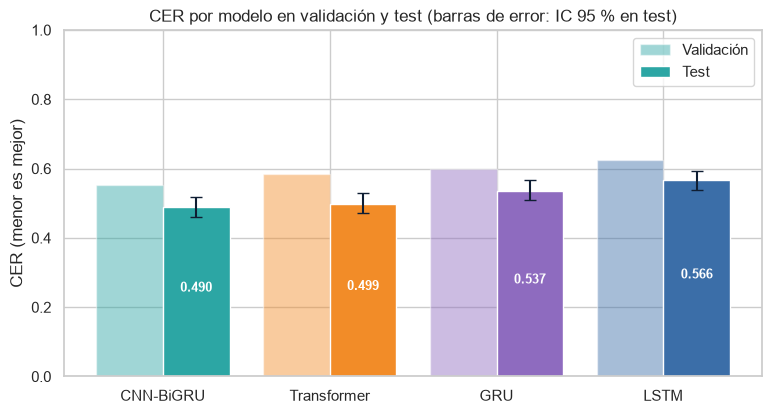

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
pos = np.arange(len(orden))
ax.bar(pos - 0.2, [reportes[m]["cer_val"] for m in orden], 0.4, color=paleta, alpha=0.45, label="Validación")
ax.bar(pos + 0.2, significancia["cer_test"], 0.4, color=paleta, label="Test",
       yerr=[significancia["cer_test"] - significancia["ic95_bajo"], significancia["ic95_alto"] - significancia["cer_test"]],
       capsize=4, ecolor="#0F1E33")
for x, v in zip(pos, significancia["cer_test"]):
    ax.text(x + 0.2, v / 2, f"{v:.3f}", ha="center", color="white", fontsize=9, fontweight="bold")
ax.set_xticks(pos, etiquetas)
ax.set(ylabel="CER (menor es mejor)", ylim=(0, 1), title="CER por modelo en validación y test (barras de error: IC 95 % en test)")
ax.legend()
fig.savefig(f"{FIGS}/comparacion_cer.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Costo de cada modelo

Todos se entrenaron en la misma CPU. El tiempo por secuencia es el promedio al predecir el conjunto de test completo.

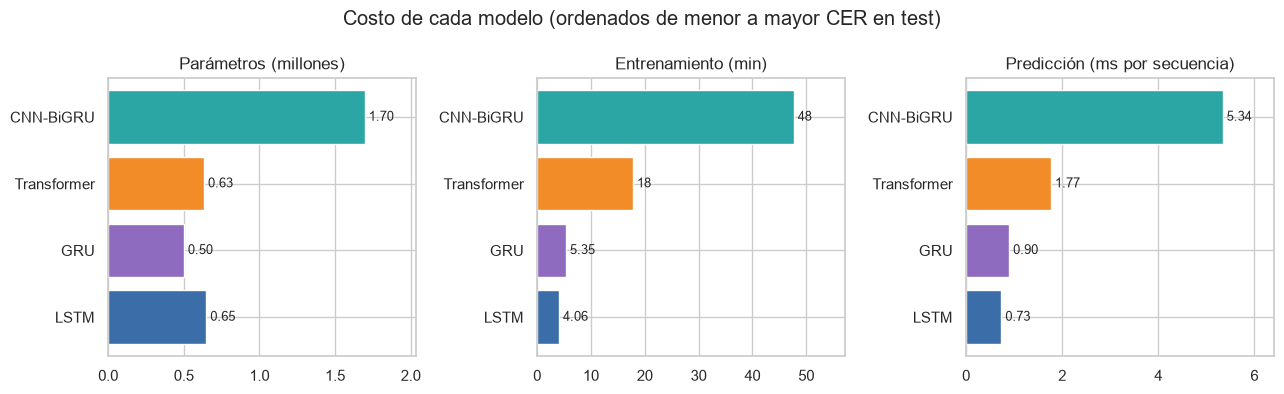

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (col, titulo) in zip(axes, [("parametros_M", "Parámetros (millones)"), ("entrenamiento_min", "Entrenamiento (min)"),
                                    ("ms_por_secuencia", "Predicción (ms por secuencia)")]):
    ax.barh(etiquetas, resumen[col], color=paleta)
    for y, v in enumerate(resumen[col]):
        ax.text(v, y, f" {v:.2f}" if v < 10 else f" {v:.0f}", va="center", fontsize=9)
    ax.set_title(titulo)
    ax.invert_yaxis()
    ax.set_xlim(0, resumen[col].max() * 1.2)
fig.suptitle("Costo de cada modelo (ordenados de menor a mayor CER en test)")
fig.tight_layout()
fig.savefig(f"{FIGS}/comparacion_costo.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Cómo aprende cada modelo

Las primeras épocas dan CER cercano a 1 porque CTC empieza prediciendo solo blanks. Importa cuándo sale cada modelo de
esa fase y si sigue bajando al final (señal de que más épocas ayudarían).

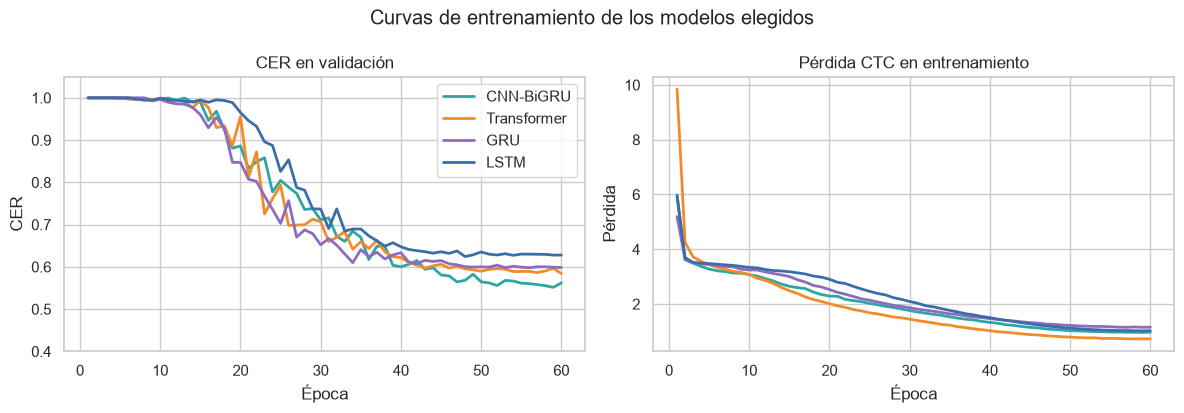

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for m in orden:
    h = reportes[m]["historial"]
    epocas = range(1, len(h["val_cer"]) + 1)
    axes[0].plot(epocas, h["val_cer"], color=COLORES.get(m), lw=2, label=NOMBRES.get(m, m))
    axes[1].plot(epocas, h["train_loss"], color=COLORES.get(m), lw=2, label=NOMBRES.get(m, m))
axes[0].set(title="CER en validación", xlabel="Época", ylabel="CER", ylim=(0.4, 1.05))
axes[1].set(title="Pérdida CTC en entrenamiento", xlabel="Época", ylabel="Pérdida")
axes[0].legend()
fig.suptitle("Curvas de entrenamiento de los modelos elegidos")
fig.tight_layout()
fig.savefig(f"{FIGS}/comparacion_curvas.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Qué tipo de error comete cada modelo

Cada error se clasifica con la alineación de mínima edición entre la frase real y la predicha: borrado (falta una
letra), sustitución (letra equivocada) o inserción (letra de más).

In [8]:
def tipos_error(predicciones):
    t = {"borrado": 0, "sustitucion": 0, "insercion": 0}
    for p in predicciones:
        for c_ref, c_hyp in metrics.alinear(p["real"], p["predicha"]):
            if not c_hyp:
                t["borrado"] += 1
            elif not c_ref:
                t["insercion"] += 1
            elif c_ref != c_hyp:
                t["sustitucion"] += 1
    return t

tipos = pd.DataFrame({NOMBRES.get(m, m): tipos_error(reportes[m]["predicciones_test"]) for m in orden}).T
(100 * tipos.div(tipos.sum(axis=1), axis=0)).round(1).assign(errores_totales=tipos.sum(axis=1))

,borrado,sustitucion,insercion,errores_totales
CNN-BiGRU,76.2,21.6,2.2,2301
Transformer,68.3,28.3,3.4,2345
GRU,66.6,30.2,3.2,2521
LSTM,62.0,34.5,3.5,2658


## 6. Qué caracteres falla cada modelo

En el EDA se vio un fuerte desbalance de caracteres. Se muestra la tasa de error en test de los caracteres con al
menos 20 apariciones en test, ordenados de más a menos frecuentes en entrenamiento.

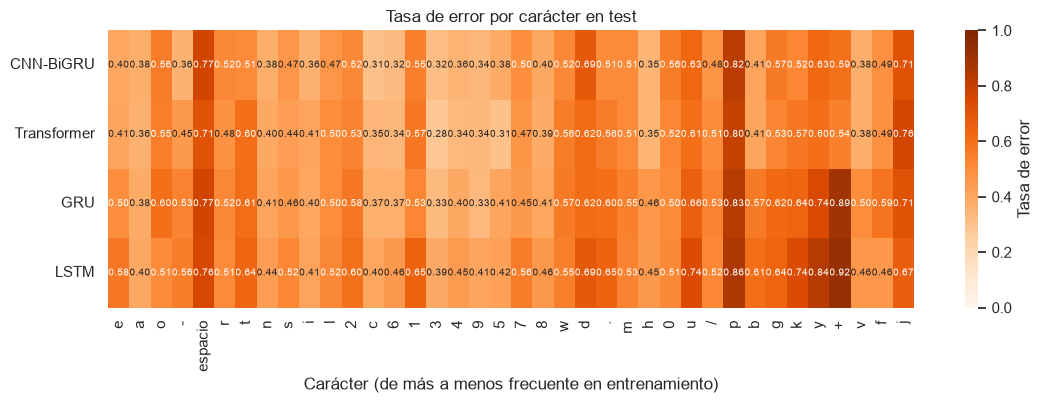

Spearman entre frecuencia en train y tasa de error:
CNN-BiGRU     -0.329
Transformer   -0.272
GRU           -0.437
LSTM          -0.364


In [9]:
cache = dataset.cargar_cache()
frecuencia_train = pd.Series(list("".join(cache["phrase"][dataset.indices_de(cache, "train")]))).value_counts()

tasas = pd.DataFrame({NOMBRES.get(m, m): {c: s["tasa"] for c, s in reportes[m]["cer_por_caracter"]["por_caracter"].items()
                                          if s["total"] >= 20} for m in orden})
tasas = tasas.dropna().loc[lambda t: sorted(t.index, key=lambda c: -frecuencia_train.get(c, 0))]
rho = tasas.apply(lambda col: col.corr(tasas.index.map(frecuencia_train).to_series(index=tasas.index), method="spearman"))
tasas.index = ["espacio" if c == " " else c for c in tasas.index]

fig, ax = plt.subplots(figsize=(13, 3.6))
sns.heatmap(tasas.T, cmap="Oranges", vmin=0, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7},
            cbar_kws={"label": "Tasa de error"}, ax=ax)
ax.set(xlabel="Carácter (de más a menos frecuente en entrenamiento)", ylabel="",
       title="Tasa de error por carácter en test")
fig.savefig(f"{FIGS}/comparacion_error_caracter.png", dpi=150, bbox_inches="tight")
plt.show()

print("Spearman entre frecuencia en train y tasa de error:")
print(rho.round(3).to_string())

## 7. ¿Afectan igual los faltantes de mano a todos los modelos?

El EDA mostró que la mano derecha falta en ~54.5 % de los cuadros. Se agrupan las secuencias de test por cuartil de
cobertura de mano (proporción de cuadros con al menos una mano detectada) y se calcula el CER de cada grupo.

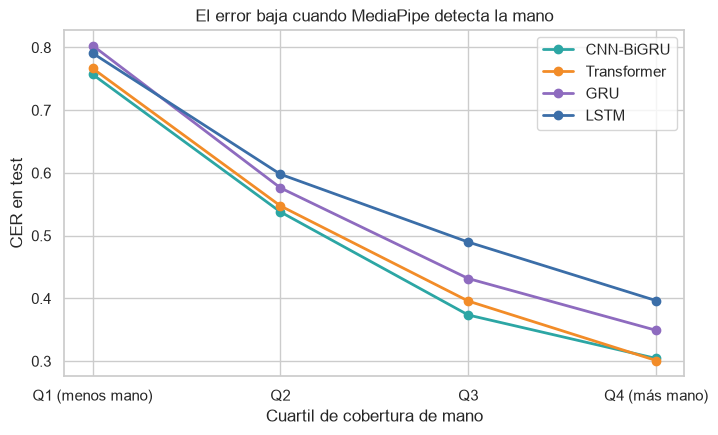

,CNN-BiGRU,Transformer,GRU,LSTM
Q1 (menos mano),0.757,0.767,0.803,0.791
Q2,0.538,0.547,0.576,0.598
Q3,0.374,0.396,0.432,0.490
Q4 (más mano),0.304,0.301,0.349,0.396


In [10]:
pos_cache = {sid: i for i, sid in enumerate(cache["sequence_id"])}
cobertura = pd.Series({sid: features.cobertura_mano(
    cache["X"][cache["offsets"][pos_cache[sid]]:cache["offsets"][pos_cache[sid] + 1], -2:].astype(np.float32)) for sid in ids})
grupo = pd.qcut(cobertura, 4, labels=["Q1 (menos mano)", "Q2", "Q3", "Q4 (más mano)"])

cer_grupo = pd.DataFrame({NOMBRES.get(m, m): por_seq[m].groupby(grupo, observed=True).sum().pipe(lambda g: g["ediciones"] / g["largo"])
                          for m in orden})
fig, ax = plt.subplots(figsize=(8, 4.5))
for m, color in zip(orden, paleta):
    ax.plot(cer_grupo.index.astype(str), cer_grupo[NOMBRES.get(m, m)], "o-", color=color, lw=2, label=NOMBRES.get(m, m))
ax.set(xlabel="Cuartil de cobertura de mano", ylabel="CER en test", title="El error baja cuando MediaPipe detecta la mano")
ax.legend()
fig.savefig(f"{FIGS}/comparacion_cobertura_mano.png", dpi=150, bbox_inches="tight")
plt.show()
cer_grupo.round(3)

## 8. Conclusiones de la comparación

- Mejor modelo: el CNN-BiGRU tiene el menor CER en test (0.490, IC 95 % de 0.461 a 0.519), pero su diferencia con el Transformer (0.499) no es significativa (Wilcoxon p = 0.21). Ambos son significativamente mejores que la GRU (0.537) y la LSTM (0.566), con p menores a 1e-6.
- Costo: el Transformer logra el mismo error con 37 % de los parámetros del CNN-BiGRU, un tercio del tiempo de entrenamiento y 3 veces menos tiempo por secuencia. Para la app es la mejor relación entre error y costo; el CNN-BiGRU es la opción si solo importa el error. Las líneas base son las más baratas (menos de 1 ms por secuencia), pero pagan unos 5 a 8 puntos de CER.
- Bidireccionalidad: los dos modelos que ven el contexto completo de cada letra le ganan a los dos que solo leen hacia adelante. Entre los unidireccionales, la GRU le gana a la LSTM con menos parámetros.
- Tipo de error: en todos los modelos dominan los borrados (62 a 76 %): ante la duda, CTC emite blank y se salta letras. El CNN-BiGRU es el que más borra y el que menos sustituye; las líneas base sustituyen más (hasta 34.5 %), o sea, se animan a emitir letras pero se equivocan más de letra.
- Hallazgos del EDA que se reflejan en todos los modelos: el desbalance de caracteres (los caracteres más frecuentes en entrenamiento se fallan menos, Spearman de -0.27 a -0.44) y sobre todo los faltantes de mano: en el cuartil con menos mano detectada todos los modelos tienen CER cercano a 0.8, y en el cuartil con más mano baja a 0.30 en los mejores. La calidad de la detección de MediaPipe limita a todos los modelos por igual, así que mejorar la entrada ayudaría más que cambiar de arquitectura.